<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 5

Title: Diabetes Classification using Ensemble Learning and Random Forests

Name: Brennen Cramp

Date: 10/25/2026

---

# Task 1: Load the dataset into a Pandas DataFrame.

The following code cell imports the UCI Pima Indians Diabetes dataset from the OpenML repository since UCI did not have the original dataset anymore. This data is then loaded into a Pandas DataFrame and update the 'outcome' feature where I will map the 'tested_negative' to 0 and 'tested_positive' to 1.

In [12]:
# Import Pandas for handling tabular data
# Import NumPy for handling scientific computing and math operations
# Import the OpenML fetch_openml to get the Pima Indians Diabetes dataset
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

# Grab the Pima Indians Diabetes dataset from OpenML, its ID=37
diabetes = fetch_openml(data_id=37, as_frame=True, parser="auto")

# Extract features/targets as DataFrames
features = diabetes.data
targets = diabetes.target

# Task 1: Combine features and targets into one DataFrame
df = pd.concat([features, targets], axis=1)

# Assign column names
# On OpenML these are the columns:
# Number of times pregnant - pregnancies
# Plasma glucose concentration a 2 hours in an oral glucose tolerance test - glucose
# Diastolic blood pressure (mm Hg) - blood_pressure
# Triceps skin fold thickness (mm) - skin_thickness
# 2-Hour serum insulin (mu U/ml) - insulin
# Body mass index (weight in kg/(height in m)^2) - bmi
# Diabetes pedigree function - diabetes_pedigree_function
# Age (years) - age
# Class variable (0 or 1) - outcome
df.columns = [
    'pregnancies', 'glucose', 'blood_pressure', 'skin_thickness',
    'insulin', 'bmi', 'diabetes_pedigree_function', 'age', 'outcome'
]

# I will map 'tested_negative' to 0 and 'tested_positive' to 1
df['outcome'] = df['outcome'].map({'tested_negative': 0, 'tested_positive': 1})


# Task 2: Inspect and analyze features.

The following code cells ***[multiple (3 total) code cells]*** are using structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

In [13]:
# Task 2: Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.
print("--- Task 2: Inspection ---")
print("\nFirst 5 rows of the dataset:")
df.head()

--- Task 2: Inspection ---

First 5 rows of the dataset:


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [14]:
print("General information about the Pima Indians Diabetes dataset:\n")
df.info()

print("\nSummary statistics of numerical columns:\n")
df.describe()

General information about the Pima Indians Diabetes dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   pregnancies                 768 non-null    int64   
 1   glucose                     768 non-null    int64   
 2   blood_pressure              768 non-null    int64   
 3   skin_thickness              768 non-null    int64   
 4   insulin                     768 non-null    int64   
 5   bmi                         768 non-null    float64 
 6   diabetes_pedigree_function  768 non-null    float64 
 7   age                         768 non-null    int64   
 8   outcome                     768 non-null    category
dtypes: category(1), float64(2), int64(6)
memory usage: 49.0 KB

Summary statistics of numerical columns:



,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


In [15]:
# IMPORTANT NOTE: outcome will not appear above since it contains categorical/object data types and is NOT numerical
# Get summary statistics for the outcome column
df['outcome'].describe()

,outcome
count,768
unique,2
top,0
freq,500


# Task 3: Quantify missing/implicit values using SimpleImputer.

The following code cell quantifies and handles any missing or implicit missing values across the columns (checking for 0s that should not be possible in certain features: glucose, blood_pressure, skin_thickness, insulin, and bmi). I also convert the 'outcome' target variable into an integer type instead of category in the entire dataframe. An additional note is that I will also just use a num_imputer after converting the 'outcome' feature into an integer type, thus no more categorical types. The code cell implements a structured imputation strategy using Scikit-Learn's SimpleImputer as well. This will NOT use .fit_transform() or .fit() to avoid data leakage.

In [16]:
# Import Scikit-Learn's SimpleImputer to handle missing entries
from sklearn.impute import SimpleImputer

# Task 3: Quantify and handle implicit missing values using SimpleImputer.
print("--- Task 3: Quantify and handle implicit missing values using SimpleImputer ---")

# Ensure the 'outcome' feature is treated as an integer type instead of category
df['outcome'] = df['outcome'].astype(int)

# Quantify missing values per column
print("\n--- Missing Value Counts ---")
print(df.isnull().sum())

# Create list of columns where a value of 0 is a missing placeholder
zero_missing_cols = ['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']

# Quantify the missing values (0) before replacing
print("--- Count of missing values (0s) ---")
for col in zero_missing_cols:
    count_zeros = (df[col] == 0).sum()
    print(f"{col}: {count_zeros} missing rows")

# Replace the 0s with np.nan
df_missing = df.copy()
df_missing[zero_missing_cols] = df_missing[zero_missing_cols].replace(0, np.nan)

# Quantify the missing values per column, again
print("\n--- New Missing Value Counts ---")
print(df_missing.isnull().sum())

# --- IMPORTANT NOTE: ---
# I will NOT use .fit_transform() during this step, on the training data, to avoid data leaks from my
# testing data into my training phase.

# Next, I want to define the numeric columns using the median (instead of mean due to extreme outliers possibly skewing the mean)
print("Defining the imputer for the numeric columns using the median values per column.")
num_imputer = SimpleImputer(missing_values=np.nan, strategy='median')

print("Imputation strategies successfully defined!")

--- Task 3: Quantify and handle implicit missing values using SimpleImputer ---

--- Missing Value Counts ---
pregnancies                   0
glucose                       0
blood_pressure                0
skin_thickness                0
insulin                       0
bmi                           0
diabetes_pedigree_function    0
age                           0
outcome                       0
dtype: int64
--- Count of missing values (0s) ---
glucose: 5 missing rows
blood_pressure: 35 missing rows
skin_thickness: 227 missing rows
insulin: 374 missing rows
bmi: 11 missing rows

--- New Missing Value Counts ---
pregnancies                     0
glucose                         5
blood_pressure                 35
skin_thickness                227
insulin                       374
bmi                            11
diabetes_pedigree_function      0
age                             0
outcome                         0
dtype: int64
Defining the imputer for the numeric columns using the median v

# Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

The following code cell isolates numerical features, then builds a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (only StandardScaler) to numerical columns; there are no categorical columns in this dataset thus I will not need to scale those. This section will also include splitting the data as to avoid any possibilities of data leakage!

In [17]:
# Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

# Import needed functionalities from Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print("--- Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline ---")

# Create X (features) and y (outcome)
X = df_missing.drop(columns=['outcome'])
y = df_missing['outcome']

# Splits the data using an 80/20 split (20% for test) and I will also set the random seed to be 100.
# I set stratify along the target to keep balance of diabetes present vs healthy patients identical in both of my sets.
test_ratio = 0.2
seed = 100
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_ratio, random_state=seed, stratify=y
)

# Get the list of all numeric feature names
num_cols = X.columns.tolist()

# Create individual pipeline for the numeric features using my median imputer from Task 3 and StandardScaler
num_transformer = Pipeline(steps=[
    ('imputer', num_imputer),
    ('scaler', StandardScaler())
])

# Make the preprocessor with the StandardScaler for numerical features by combining the pipelines into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols)
    ]
)

print("\nSuccessfully built the StandardScaler preprocessor pipeline!")

--- Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline ---

Successfully built the StandardScaler preprocessor pipeline!


# Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.

The following code cell instantiates and trains both pipelines for StandardScaler by appending a classifier (hard/soft voting classifiers) onto the preprocessor, respectively. Each preprocessor will also fit the pipeline on X_train and y_train, make predictions on X_test, and will print the evaluations (a Classification Report and accuracy Score) per pipeline. The results for accuracy will be displayed in a neat bar chart as well.

--- Task 5: Hard/Soft Voting Classifiers Training & Evaluation ---

-------------------- Start of Hard Voting Classifier --------------------

-- Classification Report for Hard Voting Classifier: --
              precision    recall  f1-score   support

           0       0.79      0.90      0.84       100
           1       0.75      0.56      0.64        54

    accuracy                           0.78       154
   macro avg       0.77      0.73      0.74       154
weighted avg       0.78      0.78      0.77       154


-------------------------------------------

Test Accuracy for Hard Voting Classifier: 0.7792

-------------------- End of Hard Voting Classifier --------------------

-------------------- Start of Soft Voting Classifier --------------------

-- Classification Report for Soft Voting Classifier: --
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       100
           1       0.63      0.61      0.62        54

    accura

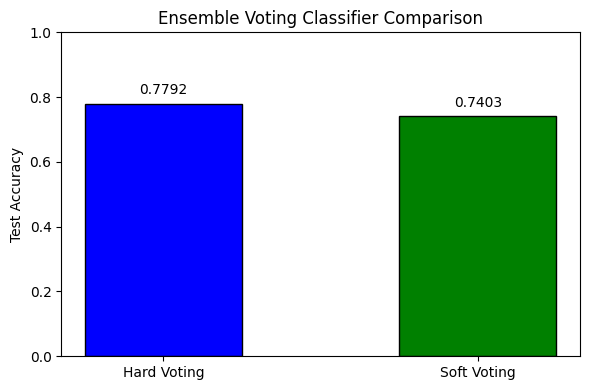

In [21]:
# Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression,
# Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports.
# Use must use appropriate plots to show the results.

# Import needed functionalities from Scikit-Learn
# Import classifiers, metrics, and visualization tools
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

print("--- Task 5: Hard/Soft Voting Classifiers Training & Evaluation ---")

# Define the individual base models and I set the probability=True for the svm_model which is required for soft voting
log_reg = LogisticRegression(random_state=seed, max_iter=1000)
svm_model = SVC(random_state=seed, probability=True)
dt_model = DecisionTreeClassifier(random_state=seed)

# Creates base estimators
estimators_list = [
    ('lr', log_reg),
    ('svc', svm_model),
    ('dt', dt_model)
]

# Builds the hard voting classifier and wraps it in a pipeline
hard_voting = VotingClassifier(estimators=estimators_list, voting='hard')
pipeline_hard = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', hard_voting)
])

# Builds the soft voting classifier and wraps it in a pipeline
soft_voting = VotingClassifier(estimators=estimators_list, voting='soft')
pipeline_soft = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', soft_voting)
])

# Train the hard voting classifier
# IMPORTANT: Fit the pipeline ONLY on the training data to prevent data leakage!!
pipeline_hard.fit(X_train, y_train)
y_pred_hard = pipeline_hard.predict(X_test)
acc_hard = accuracy_score(y_test, y_pred_hard)

# Computes and prints eval metrics for hard voting
print(f"\n-------------------- Start of Hard Voting Classifier --------------------")
print("\n-- Classification Report for Hard Voting Classifier: --")
print(classification_report(y_test, y_pred_hard))
print("\n-------------------------------------------")

print(f"\nTest Accuracy for Hard Voting Classifier: {acc_hard:.4f}")
print(f"\n-------------------- End of Hard Voting Classifier --------------------")

# Train the soft voting classifier
# IMPORTANT: Fit the pipeline ONLY on the training data to prevent data leakage!!
pipeline_soft.fit(X_train, y_train)
y_pred_soft = pipeline_soft.predict(X_test)
acc_soft = accuracy_score(y_test, y_pred_soft)

# Computes and prints eval metrics for soft voting
print(f"\n-------------------- Start of Soft Voting Classifier --------------------")
print("\n-- Classification Report for Soft Voting Classifier: --")
print(classification_report(y_test, y_pred_soft))
print("\n-------------------------------------------")

print(f"\nTest Accuracy for Soft Voting Classifier: {acc_soft:.4f}")
print(f"\n-------------------- End of Soft Voting Classifier --------------------")

# Styling for the combined plot
plt.figure(figsize=(6, 4))
voting_types = ['Hard Voting', 'Soft Voting']
accuracies = [acc_hard, acc_soft]
bars = plt.bar(voting_types, accuracies, color=['blue', 'green'], edgecolor='black', width=0.5)
plt.ylabel('Test Accuracy')
plt.title('Ensemble Voting Classifier Comparison')

# Set the limits from 0-1
plt.ylim(0, 1.0)

# Adds the value on top of the bars for clearer rep
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.02, f'{height:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.

The following code cell instantiates and trains a Bagging Classifier using Decision Trees as the base estimators and computes both the out-of-bag (OOB) score along with the held-out test accuracy. To maintain the data leakage protections, I will pre-transform the training and testing data using the fitted preprocessor from Task 4, fit the ensemble model, and then generate a bar chart for comparison.

--- Task 6: Bagging Classifier with Out-of-Bag Evaluation ---

-------------------- Bagging Evaluation --------------------
Out-of-Bag (OOB) Score: 0.7459
Held-Out Test Accuracy: 0.7857
--------------------------------------------------------------


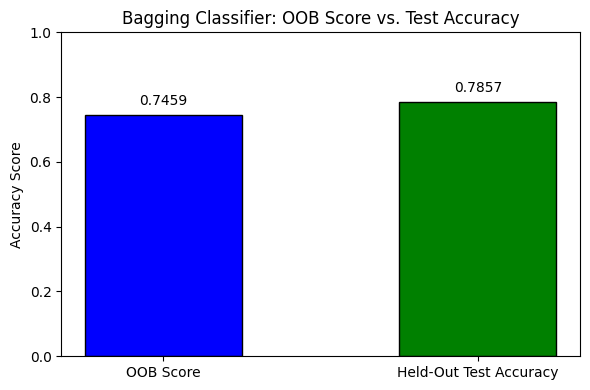

In [22]:
# Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag
# evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph.

# Import needed Bagging Classifier from Scikit-Learn
from sklearn.ensemble import BaggingClassifier

print("--- Task 6: Bagging Classifier with Out-of-Bag Evaluation ---")

# I will need to transform the datasets first for the OOB calculation within the model's fit stage
X_train_scaled = preprocessor.fit_transform(X_train, y_train)
X_test_scaled = preprocessor.transform(X_test)

# Instantiates the bagging classifier using DT base estimators, enabling bootstrap and OOB evaluation
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=seed),
    n_estimators=500,
    bootstrap=True,
    oob_score=True,
    random_state=seed,
    n_jobs=-1
)

# Fits the bagging model exclusively on the scaled train set
bagging_model.fit(X_train_scaled, y_train)

# Extracts the OOB evaluation score
oob_score = bagging_model.oob_score_

# Computes and prints eval metrics for bagging
y_pred_bag = bagging_model.predict(X_test_scaled)
acc_bag_test = accuracy_score(y_test, y_pred_bag)

print(f"\n-------------------- Bagging Evaluation --------------------")
print(f"Out-of-Bag (OOB) Score: {oob_score:.4f}")
print(f"Held-Out Test Accuracy: {acc_bag_test:.4f}")
print(f"--------------------------------------------------------------")

# Styling for the combined plot
plt.figure(figsize=(6, 4))
metrics = ['OOB Score', 'Held-Out Test Accuracy']
scores = [oob_score, acc_bag_test]

bars = plt.bar(metrics, scores, color=['blue', 'green'], edgecolor='black', width=0.5)
plt.ylabel('Accuracy Score')
plt.title('Bagging Classifier: OOB Score vs. Test Accuracy')

# Set the limits from 0-1
plt.ylim(0, 1.0)

# Adds the value on top of the bars for clearer rep
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.02, f'{height:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

The following code cell instantiates and trains a Random Forest Classifier on the preprocessed training data. After evaluation, the feature_importances_ array will be extracted (which computes Mean Decrease in Impurity) and will be mapped back to the column names to create a clear bar chart.

--- Task 7: Random Forest Classifier & Feature Importances ---

-------------------- Random Forest Performance --------------------

-- Classification Report for Random Forest: --
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       100
           1       0.71      0.67      0.69        54

    accuracy                           0.79       154
   macro avg       0.77      0.76      0.76       154
weighted avg       0.78      0.79      0.78       154


-------------------------------------------
Test Accuracy for Random Forest: 0.7857
---------------------------------------------------------------------


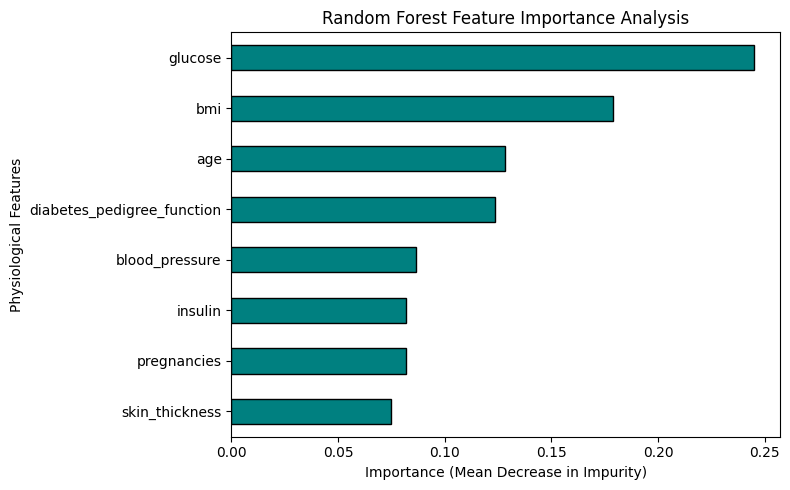

In [24]:
# Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and
# generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

# Import needed functionality from Scikit-Learn
from sklearn.ensemble import RandomForestClassifier

print("--- Task 7: Random Forest Classifier & Feature Importances ---")

# Instantiates the Random Forest model and I set max_features="sqrt" for standard random feature subsetting
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    random_state=seed,
    n_jobs=-1
)

# Fits the model on the scaled train set
rf_model.fit(X_train_scaled, y_train)

# Computes and prints eval metrics for random forest
y_pred_rf = rf_model.predict(X_test_scaled)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"\n-------------------- Random Forest Performance --------------------")
print("\n-- Classification Report for Random Forest: --")
print(classification_report(y_test, y_pred_rf))
print("\n-------------------------------------------")

print(f"Test Accuracy for Random Forest: {acc_rf:.4f}")
print(f"---------------------------------------------------------------------")

# Grab and sort feature importances (mean decrease in impurity)
importances = rf_model.feature_importances_
feature_names = num_cols

# I used a Pandas series to organize and sort the values
rf_importances = pd.Series(importances, index=feature_names).sort_values(ascending=True)

# Styling for the plot
plt.figure(figsize=(8, 5))
rf_importances.plot(kind='barh', color='teal', edgecolor='black')
plt.xlabel('Importance (Mean Decrease in Impurity)')
plt.ylabel('Physiological Features')
plt.title('Random Forest Feature Importance Analysis')
plt.tight_layout()
plt.show()

# Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

The following code cell will transition to a sequential ensemble method where I am training an AdaBoost Classifier utilizing decision stumps (a DecisionTreeClassifier with max_depth=1) as the base estimators. The model's accuracy will then be computed for both the training and test data where the values will be combined into a bar chart for comparison.

--- Task 8: AdaBoost Classifier Training & Generalization Trends ---

-------------------- AdaBoost Performance --------------------

-- Classification Report for AdaBoost (Test Data): --
              precision    recall  f1-score   support

           0       0.78      0.89      0.83       100
           1       0.72      0.54      0.62        54

    accuracy                           0.77       154
   macro avg       0.75      0.71      0.72       154
weighted avg       0.76      0.77      0.76       154


-------------------------------------------
Training Accuracy Score: 0.7899
Held-Out Test Accuracy Score: 0.7662
----------------------------------------------------------------


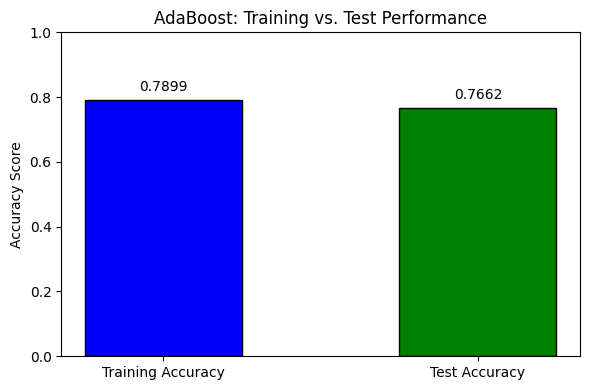

In [25]:
# Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its
# training versus test performance to observe potential boosting generalization trends. Plot the results.

# Import needed functionality from Scikit-Learn
from sklearn.ensemble import AdaBoostClassifier

print("--- Task 8: AdaBoost Classifier Training & Generalization Trends ---")

# Instantiates the weak base learner using a decision stump with max_depth=1
base_stump = DecisionTreeClassifier(max_depth=1, random_state=seed)

# Instantiates the AdaBoost Classifier using the decision stumps
ada_model = AdaBoostClassifier(
    estimator=base_stump,
    n_estimators=500,
    learning_rate=0.1,
    random_state=seed
)

# Fits the AdaBoost model on the scaled train set
ada_model.fit(X_train_scaled, y_train)

# ---- Computes and prints eval metrics for AdaBoost ----
# Predicts on the train data
y_pred_ada_train = ada_model.predict(X_train_scaled)
acc_ada_train = accuracy_score(y_train, y_pred_ada_train)

# Predicts on the held-out test data
y_pred_ada_test = ada_model.predict(X_test_scaled)
acc_ada_test = accuracy_score(y_test, y_pred_ada_test)

print(f"\n-------------------- AdaBoost Performance --------------------")
print("\n-- Classification Report for AdaBoost (Test Data): --")
print(classification_report(y_test, y_pred_ada_test))
print("\n-------------------------------------------")
print(f"Training Accuracy Score: {acc_ada_train:.4f}")
print(f"Held-Out Test Accuracy Score: {acc_ada_test:.4f}")
print(f"----------------------------------------------------------------")

# Styling for the combined plot
plt.figure(figsize=(6, 4))
split_types = ['Training Accuracy', 'Test Accuracy']
ada_scores = [acc_ada_train, acc_ada_test]
bars = plt.bar(split_types, ada_scores, color=['blue', 'green'], edgecolor='black', width=0.5)
plt.ylabel('Accuracy Score')
plt.title('AdaBoost: Training vs. Test Performance')

# Set the limits from 0-1
plt.ylim(0, 1.0)

# Adds the value on top of the bars for clearer rep
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.02, f'{height:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()